# Unit 2 – Exploratory Data Analysis (EDA)
**Module:** Machine Learning (ML_PCOM7E)  |  **Activity:** e-Portfolio EDA exercise

**Aim:** follow the EDA steps from the unit (understand the data, check quality, spot anomalies, explore relationships visually, prepare features for ML) on a real tabular dataset.

Dataset: *Wine* (UCI, bundled with scikit-learn so the notebook runs offline in Colab or Jupyter). 178 samples, 13 chemical features, 3 cultivars.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
sns.set_theme(style="whitegrid"); pd.set_option("display.width",140)
OUT="figures_unit02_"
wine = load_wine(as_frame=True)
df = wine.frame.copy()
df["cultivar"] = df["target"].map(dict(enumerate(wine.target_names)))
print(df.shape); df.head()

(178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target,cultivar
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0,class_0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0,class_0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0,class_0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0,class_0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0,class_0


## 1. Understand the dataset

In [2]:
print(df.dtypes.value_counts()); print(); df.describe().T.round(2)

float64    13
int64       1
str         1
Name: count, dtype: int64



,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


## 2. Data quality: missing values and duplicates

In [3]:
print("Missing values per column:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print(df["cultivar"].value_counts())

Missing values per column: 0
Duplicate rows: 0
cultivar
class_1    71
class_0    59
class_2    48
Name: count, dtype: int64


## 3. Spot anomalies (IQR rule)
A value is flagged when it lies more than 1.5 × IQR beyond the quartiles. Change `K` to see how strict the rule is.

magnesium            4
alcalinity_of_ash    4
color_intensity      4
malic_acid           3
ash                  3
proanthocyanins      2
hue                  1
dtype: int64
Rows with at least one flagged value: 17 of 178


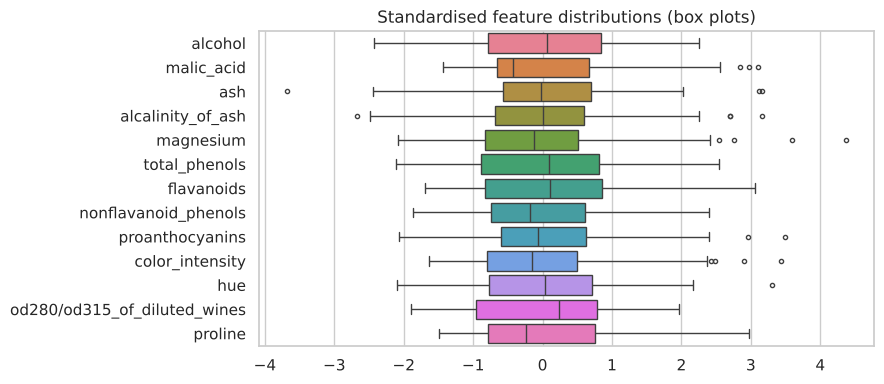

In [4]:
K = 1.5
feats = wine.feature_names
q1, q3 = df[feats].quantile(.25), df[feats].quantile(.75); iqr = q3-q1
mask = (df[feats] < q1-K*iqr) | (df[feats] > q3+K*iqr)
outliers = mask.sum().sort_values(ascending=False)
print(outliers[outliers>0])
print("Rows with at least one flagged value:", int(mask.any(axis=1).sum()), "of", len(df))
fig, ax = plt.subplots(figsize=(9,4)); sns.boxplot(data=pd.DataFrame(StandardScaler().fit_transform(df[feats]),columns=feats),orient="h",ax=ax,fliersize=3)
ax.set_title("Standardised feature distributions (box plots)"); plt.tight_layout(); plt.savefig(OUT+"boxplots.png",dpi=130); plt.show()

## 4. Visual analysis: distributions and relationships

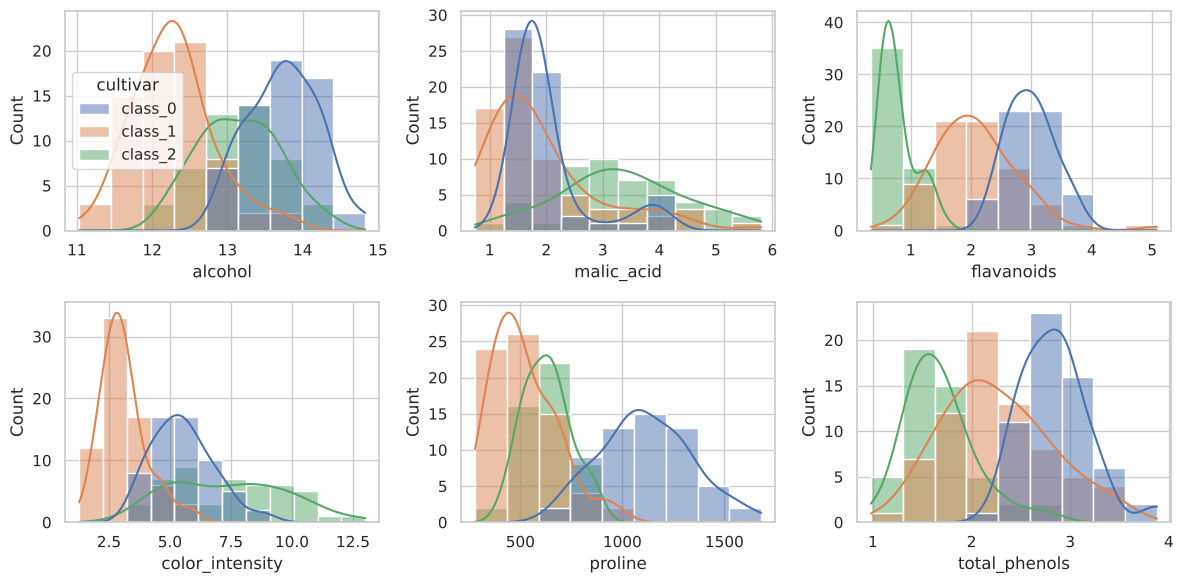

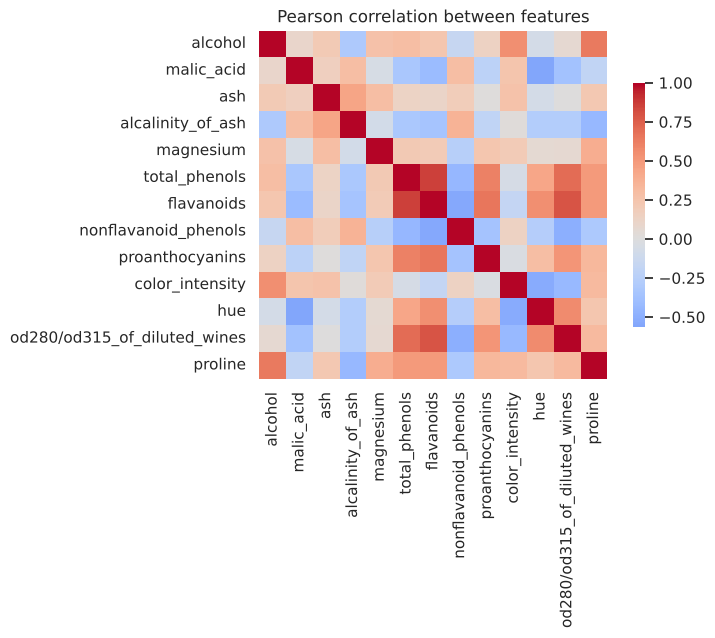

Strongest feature pairs:
total_phenols  flavanoids                      0.865
flavanoids     od280/od315_of_diluted_wines    0.787
total_phenols  od280/od315_of_diluted_wines    0.700
flavanoids     proanthocyanins                 0.653
alcohol        proline                         0.644
dtype: float64


In [5]:
fig, axes = plt.subplots(2,3, figsize=(12,6))
for a, f in zip(axes.ravel(), ["alcohol","malic_acid","flavanoids","color_intensity","proline","total_phenols"]):
    sns.histplot(data=df, x=f, hue="cultivar", kde=True, ax=a, legend=(f=="alcohol"))
plt.tight_layout(); plt.savefig(OUT+"histograms.png",dpi=130); plt.show()
corr = df[feats].corr()
plt.figure(figsize=(8,6.5)); sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink":.7})
plt.title("Pearson correlation between features"); plt.tight_layout(); plt.savefig(OUT+"correlation.png",dpi=130); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack().sort_values(key=abs, ascending=False)
print("Strongest feature pairs:"); print(pairs.head(5).round(3))

## 5. Prepare for machine learning

In [6]:
scaled = pd.DataFrame(StandardScaler().fit_transform(df[feats]), columns=feats)
print("Mean ~0 and std ~1 after scaling:", scaled.mean().abs().max().round(6), scaled.std(ddof=0).round(3).unique())
sel = df[feats].corrwith(df["target"]).abs().sort_values(ascending=False)
print("\nFeatures most associated with the cultivar label (|r|):"); print(sel.head(5).round(3))

Mean ~0 and std ~1 after scaling: 0.0 [1.]

Features most associated with the cultivar label (|r|):
flavanoids                      0.847
od280/od315_of_diluted_wines    0.788
total_phenols                   0.719
proline                         0.634
hue                             0.617
dtype: float64


## 6. Findings
* No missing values or duplicates, so no imputation was needed; the IQR rule flagged values in 17 of 178 rows (mainly magnesium, alcalinity of ash and colour intensity). They were kept because they are plausible chemical measurements rather than recording errors.
* Features sit on very different scales (proline in the hundreds, hue below 2), so scaling is needed for distance-based and gradient-based models.
* Several features are strongly correlated (e.g. flavanoids with total phenols), which warns of redundancy and multicollinearity before regression.
* Flavanoids, the OD280/OD315 ratio and proline are the features most associated with the cultivar label (|r| = 0.85, 0.79, 0.63), which suggests a classifier or clustering would work well. Flavanoids and total phenols are correlated at r = 0.87, so one of them is largely redundant.